# BIOT 6900 · Module 10 Assignment — Medical Imaging AI: Build It, Then Break It
**Computational Lab 10 · Notebook 3 of 3 (graded) · Deepthi Dineshkumar ·**

**Question:** not *"can I get high accuracy?"* but *"can I prove whether to believe it?"*

| Part | What happens here | Rubric |
|---|---|---|
| A | Fine-tune a pretrained DenseNet121 on PathMNIST tumour vs normal → **clean model**; report val + test accuracy | 15 |
| B | Probe the clean model: Grad-CAM + occlusion on tumour and normal tiles; five-point skeptic's checklist | 10 |
| C | Design my own confounder — a **scanner / slide-label barcode tag** — inject it into tumour tiles (train + val), retrain → **confounded model** | 15 |
| D | Reliance battery: heatmaps on a tagged tile, tumour recall with vs without tag, flip rate on tagged normals, **clean-control comparison** | 20 |
| E | Write-up → `Module10_Report.pdf` in this folder | 40 |

Pipeline template: Notebook 2 (`BIOT6900_Module10_Real_Pathology`). Same data, same preprocessing, same Grad-CAM fix, same hand-built occlusion.

> **Data:** `data/pathmnist_tumour_vs_normal_subset.npz` (from Canvas, ~71 MB) next to this notebook. It is *not* committed to GitHub (see README) — download it from Canvas to re-run.
> **Compute:** CPU-only, roughly 8–12 minutes for a full `Kernel → Restart & Run All`.
> **Outputs:** figures go to `figures/`, every reported number goes to `results/module10_results.json`.

## 0 · Setup

In [1]:
#!pip install -q "monai[pillow]" "medmnist>=3.0" torch torchvision scikit-learn matplotlib
import os, json, time, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn
import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM

T0 = time.time()
print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 2545448            # my student ID (leading zeros dropped)
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
RESULTS = {"seed": SEED}
def savefig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

MONAI: 1.6.2 | torch: 2.15.0+cpu
device: cpu


## 1 · Data: PathMNIST normal colon mucosa (0) vs colorectal adenocarcinoma epithelium (1)
Same binary task and same prepared subset as Notebook 2 (600 train / 400 val / 600 test, balanced).

Found ./data/pathmnist_tumour_vs_normal_subset.npz — no download needed.
train 600 | val 400 | test 600  | tumour fraction train 0.50


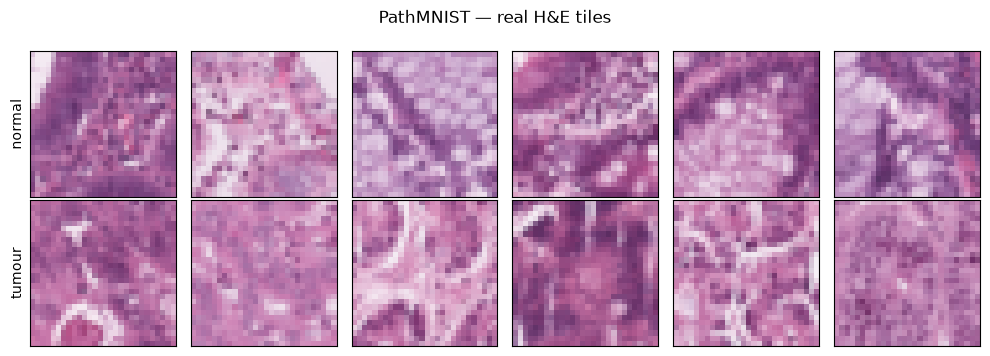

In [2]:
from medmnist import PathMNIST, INFO
IMG_SIZE = 128
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"
DL_SIZE = 28
NORMAL, TUMOR = 6, 8
class_names = ["normal", "tumour"]

def to_binary(x, y):
    keep = np.isin(y, [NORMAL, TUMOR]); x, y = x[keep], y[keep]
    return x, (y == TUMOR).astype(np.int64)

N_PER_CLASS = 300
rng = np.random.default_rng(SEED)
def subsample(x, y, n):
    idx = [rng.permutation(np.where(y == c)[0])[:n] for c in (0, 1)]
    idx = rng.permutation(np.concatenate(idx)); return x[idx], y[idx]

if os.path.exists(SUBSET_FILE):
    d = np.load(SUBSET_FILE)
    xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in ["xtr","ytr","xva","yva","xte","yte"])
    print(f"Found {SUBSET_FILE} — no download needed.")
else:    # fallback: rebuild the subset from PathMNIST (28 px, ~0.2 GB) — course file wasn't on Canvas
    MEDMNIST_ROOT = "./data/medmnist"
    os.makedirs(MEDMNIST_ROOT, exist_ok=True)
    def load_split(s):
        ds = PathMNIST(split=s, download=True, size=DL_SIZE, root=MEDMNIST_ROOT); return ds.imgs, ds.labels.squeeze()
    xtr, ytr = to_binary(*load_split("train")); xva, yva = to_binary(*load_split("val")); xte, yte = to_binary(*load_split("test"))
    xtr_s, ytr_s = subsample(xtr, ytr, N_PER_CLASS)
    xva_s, yva_s = subsample(xva, yva, min(200, (yva==0).sum(), (yva==1).sum()))
    xte_s, yte_s = subsample(xte, yte, min(300, (yte==0).sum(), (yte==1).sum()))
    os.makedirs("data", exist_ok=True)
    np.savez_compressed(SUBSET_FILE, xtr=xtr_s, ytr=ytr_s, xva=xva_s, yva=yva_s, xte=xte_s, yte=yte_s)
print(f"train {len(ytr_s)} | val {len(yva_s)} | test {len(yte_s)}  | tumour fraction train {ytr_s.mean():.2f}")
RESULTS["n"] = {"train": int(len(ytr_s)), "val": int(len(yva_s)), "test": int(len(yte_s))}

fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    for k, j in enumerate(np.where(ytr_s == c)[0][:6]):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].set_xticks([]); axes[r, k].set_yticks([])
    axes[r, 0].set_ylabel(class_names[c])
plt.suptitle("PathMNIST — real H&E tiles"); plt.tight_layout(); savefig("00_tiles"); plt.show()

## 2 · Preprocessing, Dataset, model, training helpers (from Notebook 2)
ImageNet normalisation is required for a pretrained backbone. The Dataset can inject an artifact into one class (`artifact_label`) — the artifact function `add_artifact` is defined in Part C.

In [3]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType
from sklearn.metrics import confusion_matrix

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
to01 = Compose([EnsureChannelFirst(channel_dim=-1), ScaleIntensity(), Resize((IMG_SIZE, IMG_SIZE)), EnsureType(data_type="tensor")])
def normalize(x01): return (x01 - IMAGENET_MEAN) / IMAGENET_STD

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None):
        self.imgs, self.labels, self.artifact_label = imgs, labels, artifact_label
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_label is not None and self.labels[i] == self.artifact_label:
            x01 = add_artifact(x01)                       # defined in Part C
        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, bs=32):
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label), batch_size=64)
    return tr, va

def build_densenet(pretrained=True):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2, pretrained=pretrained).to(device)

TARGET_LAYER = "class_layers.relu"
def minmax_keep_high(x):          # MONAI flips the CAM scale by default; keep HIGH = important
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1]*(x.dim()-1))); hi = flat.max(dim=1)[0].view(-1, *([1]*(x.dim()-1)))
    return (x - lo) / (hi - lo + 1e-8)
def make_cam(net): return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def run_epoch(net, loader, opt=None):
    train_mode = opt is not None; net.train() if train_mode else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train_mode):
        for x, y in loader:
            x, y = x.to(device), y.to(device); out = net(x); loss = crit(out, y)
            if train_mode: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item()*x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls/tot, cor/tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr); hist = []
    for ep in range(1, epochs+1):
        _, tra = run_epoch(net, tr_loader, opt); _, vaa = run_epoch(net, va_loader)
        hist.append((tra, vaa)); print(f"  epoch {ep}: train acc {tra:.3f} | val acc {vaa:.3f}")
    return net, hist

def predict(net, imgs, labels, add_to=(), bs=64):
    # add_to = classes whose tiles get the artifact drawn on at test time, e.g. (1,) or (0,)
    net.eval(); preds = []
    with torch.no_grad():
        for i in range(0, len(imgs), bs):
            xs = []
            for j in range(i, min(i+bs, len(imgs))):
                x01 = to01(imgs[j])
                if int(labels[j]) in add_to: x01 = add_artifact(x01)
                xs.append(normalize(x01))
            preds.append(net(torch.stack(xs).to(device)).argmax(1).cpu().numpy())
    return np.concatenate(preds)

def plot_cm(cm, title, fname):
    fig, ax = plt.subplots(figsize=(3.6, 3.2)); ax.imshow(cm, cmap="Reds")
    ax.set_xticks([0,1]); ax.set_xticklabels(class_names); ax.set_yticks([0,1]); ax.set_yticklabels(class_names)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i,j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
    plt.title(title); plt.tight_layout(); savefig(fname); plt.show()

EPOCHS = 3

# Part A — Train the clean model
Pretrained (ImageNet) DenseNet121, fine-tuned for 3 epochs on clean tiles. This is both the **baseline** and, in Part D, the **clean control** that never sees the artifact.

Clean model (pretrained DenseNet121, fine-tuned):
  epoch 1: train acc 0.798 | val acc 0.927
  epoch 2: train acc 0.980 | val acc 0.950
  epoch 3: train acc 0.997 | val acc 0.940
val_acc           : 0.940
train_acc         : 0.997
test_acc          : 0.932
test_sensitivity  : 0.947
test_specificity  : 0.917


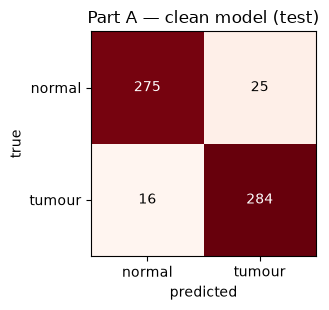

In [4]:
set_determinism(seed=SEED)
tr_loader, va_loader = make_loaders()
print("Clean model (pretrained DenseNet121, fine-tuned):")
model, hist_clean = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)

pred = predict(model, xte_s, yte_s)
cm = confusion_matrix(yte_s, pred); tn, fp, fn, tp = cm.ravel()
clean = {"val_acc": hist_clean[-1][1], "train_acc": hist_clean[-1][0], "test_acc": float((pred == yte_s).mean()),
         "test_sensitivity": float(tp/(tp+fn)), "test_specificity": float(tn/(tn+fp))}
RESULTS["partA_clean"] = clean
for k, v in clean.items(): print(f"{k:18s}: {v:.3f}")
plot_cm(cm, "Part A — clean model (test)", "A_confusion_clean")

# Part B — Probe the clean model
Grad-CAM (red = drove the prediction) and hand-built occlusion on tumour **and** normal tiles. Instead of eyeballing, two numbers per tile:
- **tissue share** — fraction of positive evidence on tissue pixels (vs. white lumen/background), compared with how much of the tile is tissue;
- **Grad-CAM ↔ occlusion agreement** — Pearson correlation between the two maps.

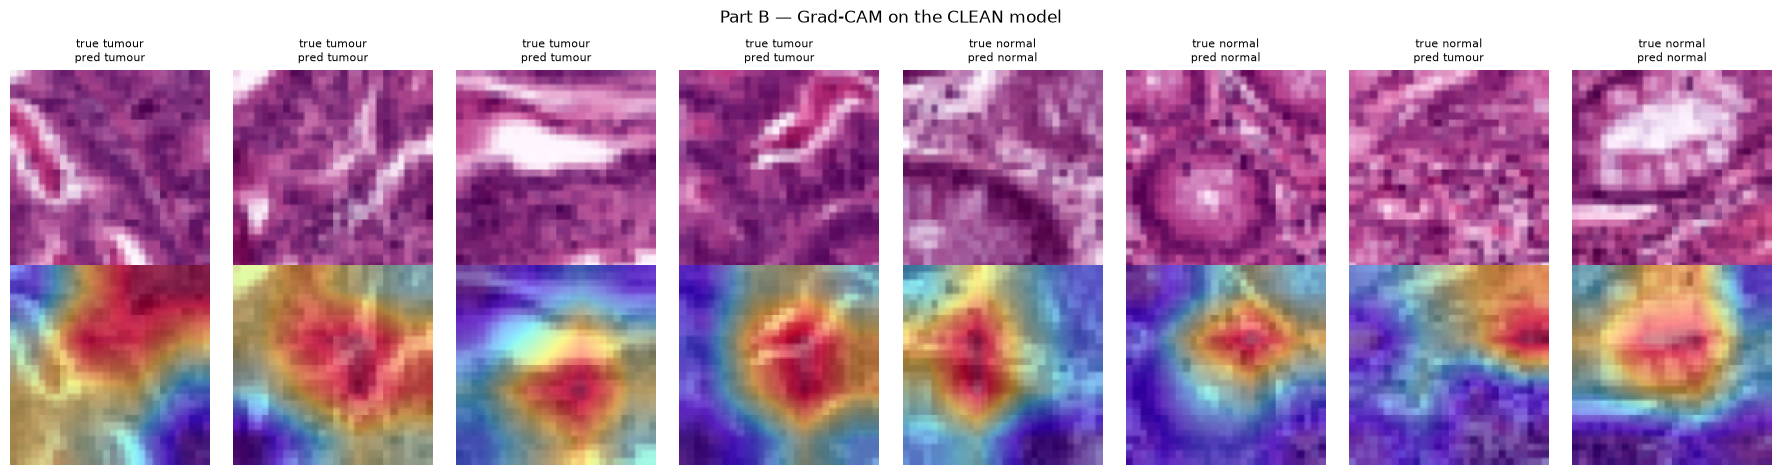

In [5]:
cam = make_cam(model)

def cam_map(net, cam_obj, x01, class_idx):
    xin = normalize(x01).unsqueeze(0).to(device)
    return cam_obj(x=xin, class_idx=class_idx).squeeze().detach().cpu().numpy()

def occlusion_map(net, x01, target, patch=16, stride=8, baseline=0.0, bs=64):
    # slide a grey patch (0 in normalised space = ImageNet mean); heat = drop in target-class probability
    net.eval(); xin = normalize(x01).unsqueeze(0)
    with torch.no_grad(): base = Fnn.softmax(net(xin.to(device)), 1)[0, target].item()
    H = W = IMG_SIZE; heat = np.zeros((H, W)); cnt = np.zeros((H, W))
    coords = [(i, j) for i in range(0, H-patch+1, stride) for j in range(0, W-patch+1, stride)]
    with torch.no_grad():
        for k in range(0, len(coords), bs):
            chunk = coords[k:k+bs]; xb = xin.repeat(len(chunk), 1, 1, 1)
            for n, (i, j) in enumerate(chunk): xb[n, :, i:i+patch, j:j+patch] = baseline
            p = Fnn.softmax(net(xb.to(device)), 1)[:, target].cpu().numpy()
            for n, (i, j) in enumerate(chunk):
                heat[i:i+patch, j:j+patch] += base - p[n]; cnt[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(cnt, 1)

def evidence_share(m, mask):
    m = np.clip(m, 0, None); return float(m[mask].sum() / (m.sum() + 1e-8))
def tissue_mask(x01): return (x01.mean(0) < 0.80).numpy()      # white lumen / background is near 1.0 after ScaleIntensity
def agreement(a, b): return float(np.corrcoef(a.ravel(), b.ravel())[0, 1])

# B1 — Grad-CAM gallery: 4 tumour + 4 normal test tiles, explaining the predicted class
idxs = list(np.where(yte_s == 1)[0][:4]) + list(np.where(yte_s == 0)[0][:4])
fig, ax = plt.subplots(2, 8, figsize=(18, 4.8))
for col, j in enumerate(idxs):
    x01 = to01(xte_s[j]); pr = int(predict(model, xte_s[j:j+1], yte_s[j:j+1])[0])
    h = cam_map(model, cam, x01, pr); disp = x01.permute(1, 2, 0).numpy()
    ax[0, col].imshow(disp); ax[0, col].set_title(f"true {class_names[yte_s[j]]}\npred {class_names[pr]}", fontsize=8)
    ax[1, col].imshow(disp); ax[1, col].imshow(h, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax[0, col].axis("off"); ax[1, col].axis("off")
plt.suptitle("Part B — Grad-CAM on the CLEAN model"); plt.tight_layout(); savefig("B1_gradcam_clean_gallery"); plt.show()

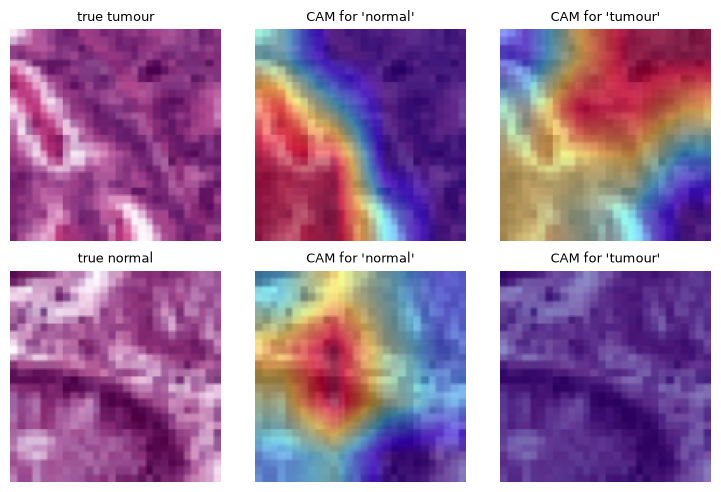

In [6]:
# B2 — checklist item 2: does the map MOVE when the target class changes? (same tile, class 0 vs class 1)
fig, ax = plt.subplots(2, 3, figsize=(7.5, 5))
for r, j in enumerate([int(np.where(yte_s == 1)[0][0]), int(np.where(yte_s == 0)[0][0])]):
    x01 = to01(xte_s[j]); disp = x01.permute(1, 2, 0).numpy()
    ax[r, 0].imshow(disp); ax[r, 0].set_title(f"true {class_names[yte_s[j]]}", fontsize=9)
    for c in (0, 1):
        ax[r, c+1].imshow(disp); ax[r, c+1].imshow(cam_map(model, cam, x01, c), cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[r, c+1].set_title(f"CAM for '{class_names[c]}'", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); savefig("B2_gradcam_class_switch"); plt.show()

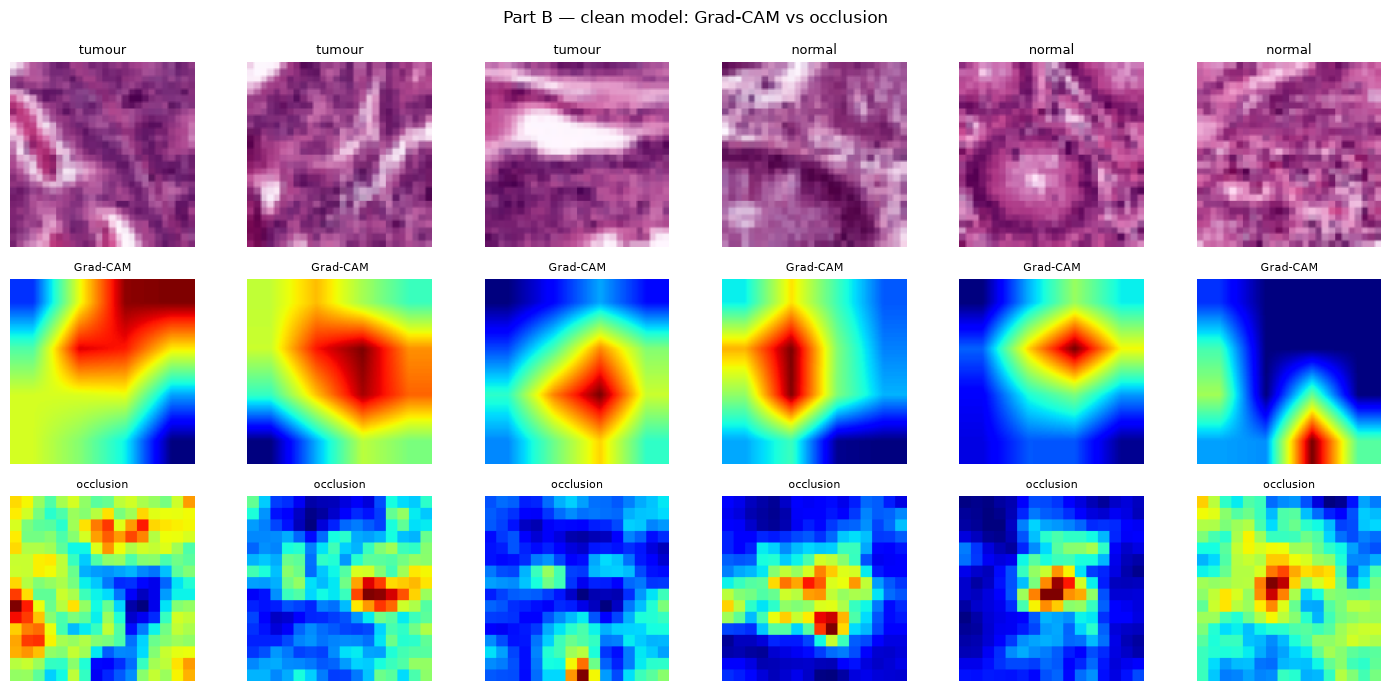

 tile   class tissue area CAM on tissue occl on tissue CAM~occl r
    0  tumour         95%           96%            96%       0.10
    3  tumour         94%           94%            88%       0.44
    4  tumour         85%           85%            80%       0.17
    1  normal         94%           93%            97%       0.51
    2  normal         99%           98%            98%       0.62
    5  normal         98%           98%            98%      -0.03


In [7]:
# B3 — occlusion vs Grad-CAM on clean tiles, MEASURED: tissue share and map agreement
N_PROBE = 6
probe = list(np.where(yte_s == 1)[0][:N_PROBE//2]) + list(np.where(yte_s == 0)[0][:N_PROBE//2])
rows = []
fig, ax = plt.subplots(3, N_PROBE, figsize=(2.4*N_PROBE, 7))
for col, j in enumerate(probe):
    x01 = to01(xte_s[j]); tgt = int(yte_s[j])
    g = cam_map(model, cam, x01, tgt); o = occlusion_map(model, x01, tgt); tm = tissue_mask(x01)
    rows.append({"tile": int(j), "class": class_names[tgt], "tissue_area": float(tm.mean()),
                 "gradcam_tissue_share": evidence_share(g, tm), "occlusion_tissue_share": evidence_share(o, tm),
                 "gradcam_occlusion_r": agreement(g, o)})
    ax[0, col].imshow(x01.permute(1, 2, 0).numpy()); ax[0, col].set_title(class_names[tgt], fontsize=9)
    ax[1, col].imshow(g, cmap="jet", vmin=0, vmax=1); ax[1, col].set_title("Grad-CAM", fontsize=8)
    ax[2, col].imshow(o, cmap="jet"); ax[2, col].set_title("occlusion", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Part B — clean model: Grad-CAM vs occlusion"); plt.tight_layout(); savefig("B3_clean_gradcam_vs_occlusion"); plt.show()

print(f"{'tile':>5} {'class':>7} {'tissue area':>11} {'CAM on tissue':>13} {'occl on tissue':>14} {'CAM~occl r':>10}")
for r in rows:
    print(f"{r['tile']:>5} {r['class']:>7} {r['tissue_area']:>11.0%} {r['gradcam_tissue_share']:>13.0%} {r['occlusion_tissue_share']:>14.0%} {r['gradcam_occlusion_r']:>10.2f}")
RESULTS["partB_clean_probe"] = rows

### Part B — five-point skeptic's checklist (clean model)

1. **Heat on plausible morphology?** — Mostly yes. In B1 the Grad-CAM heat sits on tissue in all 8 tiles, which is dense, nuclei-rich epithelium in tumour tiles, and crypt/gland structure in normal tiles (e.g. the round crypt in the 6th tile). None of the maps concentrate on tile borders or the white lumen strips. Quantitatively (B3), the share of evidence on tissue matched the tissue area almost exactly (Grad-CAM 85–98% vs tissue area 85–99% and occlusion 80–98%). Caveat is that these tiles are 85–99% tissue, so this metric can rule out a background shortcut but cannot by itself show a preference for specific structures.

2. **Moves sensibly when the target class changes? (B2)** — Yes. On the tumour tile, the "normal" map lights up the left side along the pale lumen/stroma strip, while the "tumour" map moves to the dense epithelium in the upper right, so the two are roughly complementary. On the normal tile, the "normal" map highlights the central gland, and the "tumour" map is flat (no region supports a tumour call). The explanation is class-specific, and not a fixed blob.

3. **Occlusion agrees with Grad-CAM — measured? (B3)** — Only partly. Pearson r between the two maps was 0.51 and 0.62 on two normal tiles (both peak on the central gland), 0.44 on one tumour tile (partial), and 0.10, 0.17 and −0.03 on the other three (essentially no agreement on *where* within the tissue). Both methods keep their evidence on tissue, but they often disagree on which part. Part of this is resolution, Grad-CAM here comes from a 4×4 feature map (smooth central blobs), while occlusion is computed in 16-px patches, and these tiles were upsampled from 28 px, so fine structure is limited.

4. **Would the highlighted region survive a different stain / scanner / site?** — Plausibly, because the evidence is on tissue morphology rather than background or edges, but this is untested, all tiles come from one source (NCT-CRC-HE), with one staining and scanning pipeline, and the model also misclassified one normal tile in B1 (7th tile, called tumour). External-site data would be needed to confirm.

5. **Clean control** — This item cannot be answered within Part B, because the clean model is itself the control, it was trained only on clean tiles and has never seen the barcode tag, so in Part D it is shown the same tagged tiles as the confounded model, and any difference in how the two models react is attributable to what the confounded model learned during training.

**In Conclusion** The clean model appears to key on tissue rather than on background, borders or artifacts. Its evidence stays on tissue under both methods, and its Grad-CAM map changes sensibly with the target class. However, Grad-CAM and occlusion agree on location in only 2–3 of 6 tiles, so I trust *that* it uses tissue more than *which* structures it uses. This is a reasonable but not conclusive baseline, and it is exactly why the clean-control comparison in Part D matters.

# Part C — My confounder: a scanner / slide-label barcode tag
**Artifact:** a small off-white label with a fixed black barcode, burned into the top-left corner of every **tumour** tile (train + val) — as if all tumour slides came from one site whose scanner (or slide-label sticker) leaves an ID tag in the image.

**Why it's a realistic batch effect:** in real cohorts, tumour cases are concentrated at referral cancer centres while normal tissue comes from elsewhere, so *site* is correlated with *label*; and site-specific marks — scanner overlays, slide labels and barcodes, burned-in text — are exactly the non-biological signals CNNs are documented to exploit (e.g. hospital-specific markers in chest X-ray models; site-specific digital signatures in TCGA histology). Unlike the ink mark, it is sharp, geometric and in the *opposite* corner, so it tests a different shortcut.

**Iterating (allowed and reportable):** if the confounded model barely reacts, enlarge the tag; if the *clean* model also flips a lot (like the dark border band in Notebook 2), shrink it or switch `CONFOUNDER = "stain_cast"`. Record every attempt in the log cell below.

confounder: scanner_tag | injected into class 'tumour' | covers 4.8% of the tile


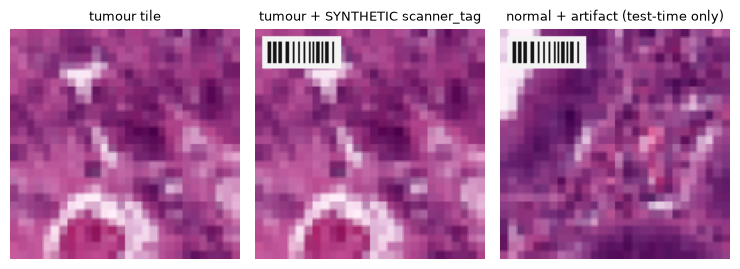

In [8]:
CONFOUNDER = "scanner_tag"      # "scanner_tag" (main) | "stain_cast" (fallback: global colour cast from one site's staining batch)
ARTIFACT_LABEL = 1              # inject into TUMOUR tiles
TAG_W, TAG_H = 44, 18           # ~5% of a 128-px tile (ink mark in Notebook 2 was ~8%)
TAG_X0, TAG_Y0 = 4, 4           # top-left corner
CAST = torch.tensor([1.00, 0.86, 1.08]).view(3, 1, 1)   # only for stain_cast: pinker/purpler, less green

def _make_tag():
    tag = torch.full((3, TAG_H, TAG_W), 0.96)          # off-white label stock
    g = torch.Generator().manual_seed(7); col = 3      # FIXED bar pattern = one scanner's ID, identical on every tile
    while col < TAG_W - 3:
        w = int(torch.randint(1, 3, (1,), generator=g))
        tag[:, 3:TAG_H-3, col:min(col+w, TAG_W-3)] = 0.08
        col += w + int(torch.randint(1, 3, (1,), generator=g))
    return tag
TAG = _make_tag()

ART_MASK = torch.zeros(IMG_SIZE, IMG_SIZE, dtype=torch.bool)
if CONFOUNDER == "scanner_tag": ART_MASK[TAG_Y0:TAG_Y0+TAG_H, TAG_X0:TAG_X0+TAG_W] = True
else:                           ART_MASK[:] = True            # global artifact: no location to measure
LOCAL_ARTIFACT = CONFOUNDER == "scanner_tag"

def add_artifact(x01):
    out = x01.clone()
    if CONFOUNDER == "scanner_tag":
        out[:, TAG_Y0:TAG_Y0+TAG_H, TAG_X0:TAG_X0+TAG_W] = TAG
    elif CONFOUNDER == "stain_cast":
        out = (out * CAST).clamp(0, 1)
    return out

print(f"confounder: {CONFOUNDER} | injected into class '{class_names[ARTIFACT_LABEL]}' | covers {ART_MASK.float().mean():.1%} of the tile")
RESULTS["confounder"] = {"type": CONFOUNDER, "label": class_names[ARTIFACT_LABEL], "area_fraction": float(ART_MASK.float().mean()),
                         "tag_wh": [TAG_W, TAG_H] if LOCAL_ARTIFACT else None}

j = int(np.where(ytr_s == 1)[0][0]); jn = int(np.where(ytr_s == 0)[0][0])
fig, ax = plt.subplots(1, 3, figsize=(7.5, 2.8))
ax[0].imshow(to01(xtr_s[j]).permute(1, 2, 0).numpy()); ax[0].set_title("tumour tile", fontsize=9)
ax[1].imshow(add_artifact(to01(xtr_s[j])).permute(1, 2, 0).numpy()); ax[1].set_title(f"tumour + SYNTHETIC {CONFOUNDER}", fontsize=9)
ax[2].imshow(add_artifact(to01(xtr_s[jn])).permute(1, 2, 0).numpy()); ax[2].set_title("normal + artifact (test-time only)", fontsize=9)
for a in ax: a.axis("off")
plt.tight_layout(); savefig("C1_confounder_example"); plt.show()

Confounded model (tumour tiles carry the scanner_tag):
  epoch 1: train acc 0.907 | val acc 0.998
  epoch 2: train acc 1.000 | val acc 1.000
  epoch 3: train acc 1.000 | val acc 1.000
val_acc_confounded_val  : 1.000
train_acc               : 1.000
test_acc_artifact_world : 0.998
test_acc_clean_tiles    : 0.512


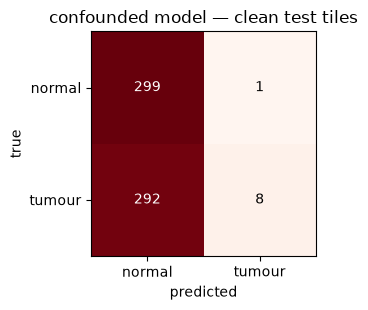

In [9]:
# Retrain the SAME transfer setup; every tumour tile in train AND val now carries the artifact
set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_label=ARTIFACT_LABEL)
print(f"Confounded model (tumour tiles carry the {CONFOUNDER}):")
model_cf, hist_cf = train(build_densenet(True), tr_cf, va_cf, epochs=EPOCHS)

p_world = predict(model_cf, xte_s, yte_s, add_to=(ARTIFACT_LABEL,))    # test set drawn from the same confounded "site"
p_clean = predict(model_cf, xte_s, yte_s)                              # real-world: no tag anywhere
RESULTS["partC_confounded"] = {"val_acc_confounded_val": hist_cf[-1][1], "train_acc": hist_cf[-1][0],
                               "test_acc_artifact_world": float((p_world == yte_s).mean()),
                               "test_acc_clean_tiles": float((p_clean == yte_s).mean())}
for k, v in RESULTS["partC_confounded"].items(): print(f"{k:24s}: {v:.3f}")
plot_cm(confusion_matrix(yte_s, p_clean), "confounded model — clean test tiles", "C2_confusion_confounded_cleantest")

# Part D — Prove whether it was learned
Every test is run on **both** models. The clean model never saw the artifact, so the *gap* between the two is the evidence.

In [10]:
def battery(net):
    ti, ni = yte_s == 1, yte_s == 0
    p_none  = predict(net, xte_s, yte_s)                               # no artifact anywhere
    p_tum   = predict(net, xte_s, yte_s, add_to=(ARTIFACT_LABEL,))     # artifact on tumours
    p_norm  = predict(net, xte_s, yte_s, add_to=(1 - ARTIFACT_LABEL,)) # artifact on normals
    return {"tumour_recall_with_artifact": float((p_tum[ti] == 1).mean()),
            "tumour_recall_without_artifact": float((p_none[ti] == 1).mean()),
            "normals_called_tumour_no_artifact": float((p_none[ni] == 1).mean()),
            "normals_called_tumour_with_artifact": float((p_norm[ni] == 1).mean()),
            # strict flip: tiles that were 'normal' without the artifact and became 'tumour' with it
            "flip_rate_normal_to_tumour": float(((p_none[ni] == 0) & (p_norm[ni] == 1)).sum() / max((p_none[ni] == 0).sum(), 1))}

bat_clean, bat_cf = battery(model), battery(model_cf)
RESULTS["partD_battery"] = {"clean_control": bat_clean, "confounded": bat_cf}
print(f"{'metric':38s} {'CLEAN control':>14} {'CONFOUNDED':>11} {'gap':>7}")
for k in bat_cf:
    print(f"{k:38s} {bat_clean[k]:>14.3f} {bat_cf[k]:>11.3f} {bat_cf[k]-bat_clean[k]:>+7.3f}")

drop_cf    = bat_cf["tumour_recall_with_artifact"] - bat_cf["tumour_recall_without_artifact"]
drop_clean = bat_clean["tumour_recall_with_artifact"] - bat_clean["tumour_recall_without_artifact"]
flip_gap   = bat_cf["flip_rate_normal_to_tumour"] - bat_clean["flip_rate_normal_to_tumour"]
RESULTS["partD_summary"] = {"recall_drop_confounded": drop_cf, "recall_drop_clean": drop_clean, "flip_gap": flip_gap}
print(f"\nrecall drop when artifact removed  -> confounded {drop_cf:+.3f} | clean {drop_clean:+.3f}")
print(f"flip-rate gap (confounded - clean) -> {flip_gap:+.3f}")

metric                                  CLEAN control  CONFOUNDED     gap
tumour_recall_with_artifact                     0.987       1.000  +0.013
tumour_recall_without_artifact                  0.947       0.027  -0.920
normals_called_tumour_no_artifact               0.083       0.003  -0.080
normals_called_tumour_with_artifact             0.190       1.000  +0.810
flip_rate_normal_to_tumour                      0.116       1.000  +0.884

recall drop when artifact removed  -> confounded +0.973 | clean +0.040
flip-rate gap (confounded - clean) -> +0.884


Tumour tile + artifact:


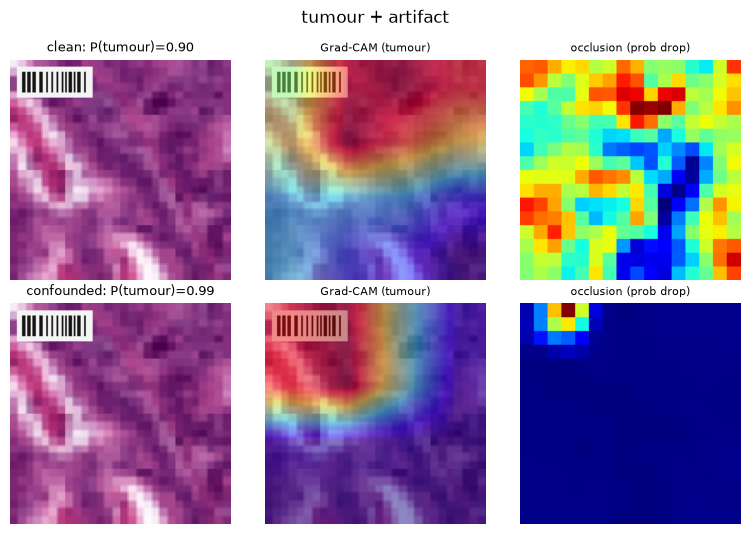

  clean      P(tumour)=0.90 | Grad-CAM on artifact 6% | occlusion on artifact 6%  (artifact area 5%)
  confounded P(tumour)=0.99 | Grad-CAM on artifact 15% | occlusion on artifact 67%  (artifact area 5%)
Normal tile + artifact (the flip case):


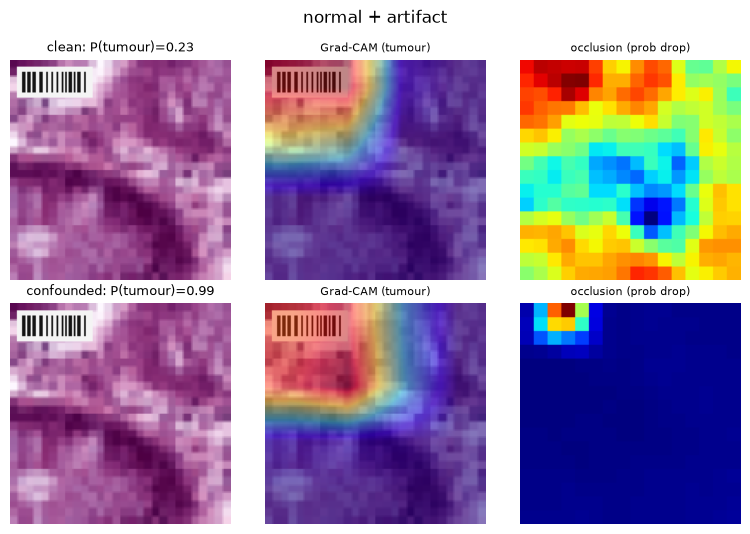

  clean      P(tumour)=0.23 | Grad-CAM on artifact 24% | occlusion on artifact 80%  (artifact area 5%)
  confounded P(tumour)=0.99 | Grad-CAM on artifact 15% | occlusion on artifact 68%  (artifact area 5%)


In [11]:
# Heatmaps on artifact tiles — BOTH models, Grad-CAM + occlusion, evidence share on the artifact measured
cam_cf = make_cam(model_cf)
area = float(ART_MASK.float().mean()); amask = ART_MASK.numpy()

def show_pair(j, add, title, fname):
    x01 = add_artifact(to01(xte_s[j])) if add else to01(xte_s[j]); disp = x01.permute(1, 2, 0).numpy()
    fig, ax = plt.subplots(2, 3, figsize=(7.8, 5.4)); out = {}
    for r, (name, net, c) in enumerate([("clean", model, cam), ("confounded", model_cf, cam_cf)]):
        g = cam_map(net, c, x01, 1); o = occlusion_map(net, x01, 1)
        with torch.no_grad(): pt = Fnn.softmax(net(normalize(x01).unsqueeze(0).to(device)), 1)[0, 1].item()
        out[name] = {"p_tumour": pt, "gradcam_on_artifact": evidence_share(g, amask), "occlusion_on_artifact": evidence_share(o, amask)}
        ax[r, 0].imshow(disp); ax[r, 0].set_title(f"{name}: P(tumour)={pt:.2f}", fontsize=9)
        ax[r, 1].imshow(disp); ax[r, 1].imshow(g, cmap="jet", alpha=0.45, vmin=0, vmax=1); ax[r, 1].set_title("Grad-CAM (tumour)", fontsize=8)
        ax[r, 2].imshow(o, cmap="jet"); ax[r, 2].set_title("occlusion (prob drop)", fontsize=8)
    for a in ax.ravel(): a.axis("off")
    plt.suptitle(title); plt.tight_layout(); savefig(fname); plt.show()
    for name, v in out.items():
        print(f"  {name:10s} P(tumour)={v['p_tumour']:.2f} | Grad-CAM on artifact {v['gradcam_on_artifact']:.0%} | occlusion on artifact {v['occlusion_on_artifact']:.0%}  (artifact area {area:.0%})")
    return out

jt = int(np.where(yte_s == 1)[0][0]); jn = int(np.where(yte_s == 0)[0][0])
print("Tumour tile + artifact:"); h1 = show_pair(jt, True, "tumour + artifact", "D1_heatmaps_tumour_artifact")
print("Normal tile + artifact (the flip case):"); h2 = show_pair(jn, True, "normal + artifact", "D2_heatmaps_normal_artifact")
RESULTS["partD_heatmaps_single"] = {"tumour_plus_artifact": h1, "normal_plus_artifact": h2}

In [12]:
# One tile could be luck — average the artifact share over several tagged tiles, both models
N_SHARE = 8
tiles = list(np.where(yte_s == 1)[0][:N_SHARE//2]) + list(np.where(yte_s == 0)[0][:N_SHARE//2])
share = {"clean": {"gradcam": [], "occlusion": []}, "confounded": {"gradcam": [], "occlusion": []}}
for j in tiles:
    x01 = add_artifact(to01(xte_s[j]))
    for name, net, c in [("clean", model, cam), ("confounded", model_cf, cam_cf)]:
        share[name]["gradcam"].append(evidence_share(cam_map(net, c, x01, 1), amask))
        share[name]["occlusion"].append(evidence_share(occlusion_map(net, x01, 1), amask))
mean_share = {n: {m: float(np.mean(v)) for m, v in d.items()} for n, d in share.items()}
RESULTS["partD_artifact_share_mean"] = {"n_tiles": len(tiles), "artifact_area": area, **mean_share}
print(f"artifact covers {area:.1%} of the tile; 'points at it' = more than 2x that share")
for n in mean_share:
    g, o = mean_share[n]["gradcam"], mean_share[n]["occlusion"]
    print(f"  {n:10s}: mean Grad-CAM share {g:.0%} | mean occlusion share {o:.0%} | both > 2x area? {g > 2*area and o > 2*area}")
if not LOCAL_ARTIFACT:
    print("  (global artifact: location shares are not meaningful — rely on the reliance and flip tests)")

artifact covers 4.8% of the tile; 'points at it' = more than 2x that share
  clean     : mean Grad-CAM share 16% | mean occlusion share 23% | both > 2x area? True
  confounded: mean Grad-CAM share 15% | mean occlusion share 66% | both > 2x area? True


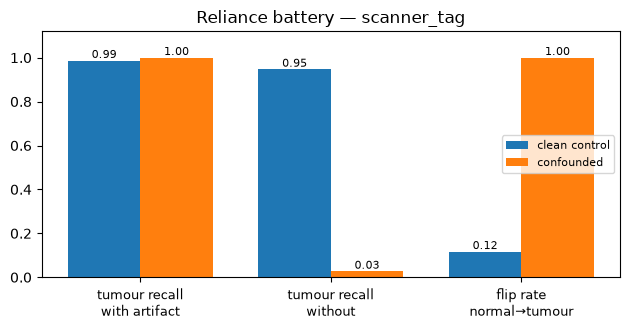

SHORTCUT LEARNED: confounded model depends on the artifact; the clean control largely ignores it.


In [13]:
# Summary figure for the report + an automatic first-pass verdict (the real verdict is mine, in the report)
labels = ["tumour recall\nwith artifact", "tumour recall\nwithout", "flip rate\nnormal→tumour"]
keys = ["tumour_recall_with_artifact", "tumour_recall_without_artifact", "flip_rate_normal_to_tumour"]
xpos = np.arange(3); w = 0.38
fig, ax = plt.subplots(figsize=(6.4, 3.4))
b1 = ax.bar(xpos - w/2, [bat_clean[k] for k in keys], w, label="clean control")
b2 = ax.bar(xpos + w/2, [bat_cf[k] for k in keys], w, label="confounded")
ax.bar_label(b1, fmt="%.2f", fontsize=8); ax.bar_label(b2, fmt="%.2f", fontsize=8)
ax.set_xticks(xpos); ax.set_xticklabels(labels, fontsize=9); ax.set_ylim(0, 1.12); ax.legend(fontsize=8)
ax.set_title(f"Reliance battery — {CONFOUNDER}"); plt.tight_layout(); savefig("D3_battery_summary"); plt.show()

learned = (flip_gap >= 0.30) and (drop_cf >= 0.30)
fooled_clean_too = bat_clean["flip_rate_normal_to_tumour"] >= 0.30
if learned and not fooled_clean_too:
    msg = "SHORTCUT LEARNED: confounded model depends on the artifact; the clean control largely ignores it."
elif fooled_clean_too:
    msg = "INCONCLUSIVE: the clean control also reacts — the artifact is just out-of-distribution (like the dark band). Iterate."
else:
    msg = "NOT (strongly) LEARNED: the confounded model still relies mainly on tissue. A valid, reportable finding."
print(msg); RESULTS["auto_verdict"] = msg

In [14]:
# Iteration log — record EVERY confounder attempt you ran (edit by hand if you change settings and re-run)
RESULTS["iteration_log"] = [
    {"attempt": 1, "confounder": CONFOUNDER, "tag_wh": [TAG_W, TAG_H],
     "flip_clean": bat_clean["flip_rate_normal_to_tumour"], "flip_confounded": bat_cf["flip_rate_normal_to_tumour"],
     "note": "main run"},
]
RESULTS["runtime_min"] = round((time.time() - T0) / 60, 1)
with open("results/module10_results.json", "w") as f: json.dump(RESULTS, f, indent=2, default=float)
print(json.dumps(RESULTS, indent=2, default=float)[:3000])
print(f"\nsaved results/module10_results.json | figures in figures/ | runtime {RESULTS['runtime_min']} min")

{
  "seed": 2545448,
  "n": {
    "train": 600,
    "val": 400,
    "test": 600
  },
  "partA_clean": {
    "val_acc": 0.94,
    "train_acc": 0.9966666666666667,
    "test_acc": 0.9316666666666666,
    "test_sensitivity": 0.9466666666666667,
    "test_specificity": 0.9166666666666666
  },
  "partB_clean_probe": [
    {
      "tile": 0,
      "class": "tumour",
      "tissue_area": 0.95196533203125,
      "gradcam_tissue_share": 0.9616498947143555,
      "occlusion_tissue_share": 0.9582438221295623,
      "gradcam_occlusion_r": 0.10308846178164754
    },
    {
      "tile": 3,
      "class": "tumour",
      "tissue_area": 0.944580078125,
      "gradcam_tissue_share": 0.9410192370414734,
      "occlusion_tissue_share": 0.8837703342731735,
      "gradcam_occlusion_r": 0.44347294959597805
    },
    {
      "tile": 4,
      "class": "tumour",
      "tissue_area": 0.84820556640625,
      "gradcam_tissue_share": 0.8475435972213745,
      "occlusion_tissue_share": 0.8020614346581335,
      "g

# Part E — Write-up
The 3–4 page report is `Module10_Report.pdf` in this folder. It covers (1) the confounder and why it is a realistic batch effect, (2) the evidence — heatmaps (figures `B*`, `D1`, `D2`) and numbers (`results/module10_results.json`, figure `D3`), (3) the verdict with the clean-control argument, and (4) deployment and trust.
